# 05 Importance, error analysis and the final feature set
**Goal:** (1) permutation importance and a temperature-noise test, (2) where the model wins and loses, (3) check whether dropping weather is better, (4) bootstrap the final model against the baseline.

**Needs:** `src/forecast_lib.py` (shared feature and CV code).

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import forecast_lib as fl
from sklearn.metrics import mean_absolute_error

h = pd.read_csv("../data/processed/hourly.csv", index_col=0, parse_dates=True)
F = fl.build_features(h)
tscv, models, REL = fl.make_tscv(), fl.MODELS, fl.REL

runs2 = {"baseline": fl.oof_from_col(F, tscv, "daytype_lag"),
         "lgbm_rel": fl.cv_predict_rel(F, tscv, models["lgbm"], REL)}

# sanity check: should match Notebook 04 (about 1886)
d = F[["actual"]].join(runs2["lgbm_rel"])
print("lgbm_rel pooled MAE:", round((d["pred"] - d["actual"]).abs().mean()))

lgbm_rel pooled MAE: 1886


In [2]:
rng = np.random.default_rng(0)

GROUPS = {
    "hour":        ["hour_sin", "hour_cos"],
    "day_type":    ["is_weekend", "dow"],
    "past_demand": ["lag_24_rel", "lag_168_rel", "yday_mean_rel"],
    "weather":     ["temp", "cdd20"],
}

rows = []
for i, (tr, te) in enumerate(tscv.split(F), start=1):
    # train on this fold's training part only
    Xtr = F.iloc[tr][REL]
    ytr = F.iloc[tr]["actual"] / F.iloc[tr]["roll_mean_7d"]
    ok = Xtr.notna().all(axis=1) & ytr.notna()
    m = models["lgbm"]().fit(Xtr[ok], ytr[ok])

    Xte = F.iloc[te][REL]
    scale = F.iloc[te]["roll_mean_7d"].to_numpy()
    yte = F.iloc[te]["actual"].to_numpy()
    base_mae = mean_absolute_error(yte, m.predict(Xte) * scale)

    # permutation importance: shuffle each group's rows jointly, 5 repeats
    for g, cols in GROUPS.items():
        incs = []
        for _ in range(5):
            Xp = Xte.copy()
            Xp[cols] = Xte[cols].sample(
                frac=1, random_state=int(rng.integers(1_000_000_000))).to_numpy()
            incs.append(mean_absolute_error(yte, m.predict(Xp) * scale) - base_mae)
        rows.append({"fold": i, "group": g, "MAE_increase": np.mean(incs)})

    # temperature noise test: stand-in for weather-forecast error (sd = 2 degC)
    incs = []
    for _ in range(5):
        Xn = Xte.copy()
        Xn["temp"] = Xte["temp"] + rng.normal(0, 2.0, len(Xn))
        Xn["cdd20"] = np.maximum(Xn["temp"] - 20, 0)
        incs.append(mean_absolute_error(yte, m.predict(Xn) * scale) - base_mae)
    rows.append({"fold": i, "group": "temp_noise_2C", "MAE_increase": np.mean(incs)})

pi = pd.DataFrame(rows).pivot(index="group", columns="fold", values="MAE_increase")
pi["mean"] = pi.mean(axis=1)
print(pi.round(0).sort_values("mean", ascending=False))

fold                 1        2        3        4        5        6     mean
group                                                                       
past_demand    16882.0  14422.0  12592.0  13001.0  13143.0  14695.0  14123.0
day_type         948.0    191.0   1033.0   1065.0    828.0   1028.0    849.0
hour             127.0    161.0    397.0    492.0    400.0    415.0    332.0
weather          266.0     79.0    -71.0    -14.0     18.0     16.0     49.0
temp_noise_2C     20.0     71.0    -24.0     -6.0      9.0      4.0     12.0


Hours in evaluation: 4032 | months covered: [7, 8, 9, 10, 11, 12]

--- by hour ---
          ae_lgbm  ae_base   gain
DateTime                         
0          1576.0   1697.0  121.0
1          1424.0   1553.0  129.0
2          1305.0   1455.0  150.0
3          1325.0   1381.0   56.0
4          1340.0   1403.0   63.0
5          1399.0   1323.0  -76.0
6          1720.0   1558.0 -163.0
7          1895.0   1748.0 -146.0
8          2166.0   2196.0   30.0
9          2290.0   2447.0  157.0
10         2275.0   2566.0  292.0
11         2354.0   2564.0  210.0
12         2385.0   2829.0  444.0
13         2271.0   2656.0  385.0
14         2137.0   2637.0  501.0
15         2120.0   2602.0  482.0
16         2015.0   2421.0  406.0
17         2190.0   2557.0  367.0
18         1940.0   2481.0  541.0
19         2039.0   2447.0  408.0
20         2069.0   2310.0  242.0
21         1737.0   2010.0  273.0
22         1856.0   1894.0   38.0
23         1438.0   1872.0  434.0

--- by weekday ---
          ae_

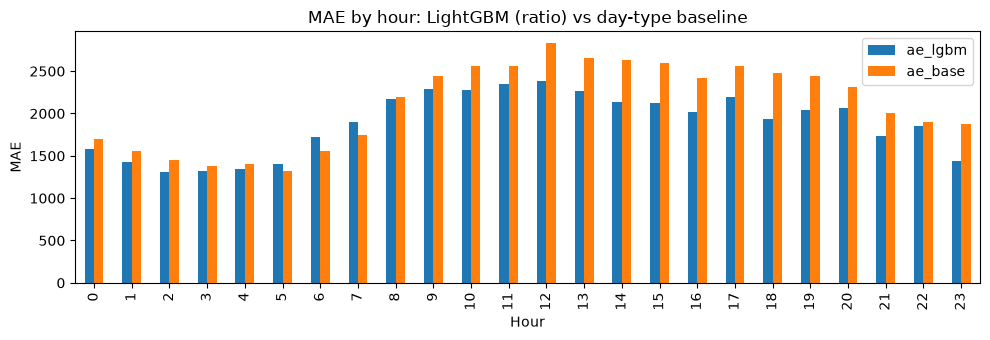

In [3]:
import matplotlib.pyplot as plt

E = F[["actual", "temp"]].join(
    runs2["lgbm_rel"][["pred"]].rename(columns={"pred": "lgbm"}), how="inner")
E["base"] = runs2["baseline"]["pred"]
for c in ["lgbm", "base"]:
    E["ae_" + c] = (E[c] - E["actual"]).abs()

def by(key):
    t = E.groupby(key, observed=True)[["ae_lgbm", "ae_base"]].mean()
    t["gain"] = t["ae_base"] - t["ae_lgbm"]      # > 0 means the model is better
    return t.round(0)

print("Hours in evaluation:", len(E), "| months covered:",
      sorted(E.index.month.unique().tolist()))

print("\n--- by hour ---")
print(by(E.index.hour))

print("\n--- by weekday ---")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(by(E.index.day_name().str[:3]).reindex(days))

print("\n--- by month ---")
print(by(E.index.month))

print("\n--- by temperature quintile ---")
print(by(pd.qcut(E["temp"], 5)))

fig, ax = plt.subplots(figsize=(10, 3.5))
by(E.index.hour)[["ae_lgbm", "ae_base"]].plot(kind="bar", ax=ax)
ax.set(title="MAE by hour: LightGBM (ratio) vs day-type baseline", xlabel="Hour", ylabel="MAE")
plt.tight_layout()
plt.savefig("../reports/figures/06_error_by_hour.png", dpi=150)
plt.show()

In [4]:
REL_NOWX = fl.REL_NOWX
oof_nowx = fl.cv_predict_rel(F, tscv, models["lgbm"], REL_NOWX)

def mae_by_fold(oof):
    d = F[["actual"]].join(oof, how="inner")
    return (d["pred"] - d["actual"]).abs().groupby(d["fold"]).mean()

cmp = pd.DataFrame({"baseline": mae_by_fold(runs2["baseline"]),
                    "lgbm_rel_weather": mae_by_fold(runs2["lgbm_rel"]),
                    "lgbm_rel_noweather": mae_by_fold(oof_nowx)})
cmp.loc["mean"] = cmp.mean()
print(cmp.round(0))

      baseline  lgbm_rel_weather  lgbm_rel_noweather
fold                                                
1       2307.0            2660.0              2406.0
2       4082.0            3017.0              3131.0
3       1608.0            1689.0              1416.0
4       1200.0            1062.0              1017.0
5       2175.0            1885.0              1872.0
6       1281.0            1003.0              1093.0
mean    2109.0            1886.0              1822.0


In [5]:
def daily_mae(oof):
    d = F[["actual"]].join(oof, how="inner")
    return (d["pred"] - d["actual"]).abs().resample("D").mean()

def boot_ci(s, block=7, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    blocks = [s.iloc[i:i+block].to_numpy() for i in range(0, len(s), block)]
    means = [np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]).mean()
             for _ in range(n)]
    return np.percentile(means, [2.5, 97.5]).round(0)

diff = (daily_mae(runs2["baseline"]) - daily_mae(oof_nowx)).dropna()   # > 0 = model better
eid = (diff.index >= "2017-09-01") & (diff.index <= "2017-09-07")
print("all days :", round(diff.mean()), boot_ci(diff))
print("excl. Eid:", round(diff[~eid].mean()), boot_ci(diff[~eid]))

all days : 286 [ 59. 555.]
excl. Eid: 136 [-19. 269.]


## Conclusion
- Permutation importance (grouped, LightGBM ratio model): past demand >> day type > hour > weather. The hour score is low only because the ratio lags already carry the hourly shape. Read the ranking, not the sizes.
- Weather is about zero (49), and 2 degC of temperature noise adds only 12 MAE. Random noise only; real forecast errors can be systematic.
- The model gains on afternoons (hours 12-19), weekends, Monday and September; it loses on Tue-Thu, in the morning ramp-up (hours 5-7) and in August, and has almost no edge in the hottest quintile. Only Jul-Dec was tested (the first test fold starts Jul 16).
- **Final model: LightGBM on load ratios, no weather.** Mean MAE 1,822 vs 2,109 for the baseline (-13.6%), beating it in 5 of 6 folds (loses fold 1: 2,406 vs 2,307), so it still fails the every-fold rule.
- Bootstrap gain: 286 [59, 555] over all days, 136 [-19, 269] excluding Eid week. About 12 variants were selected on the same folds.
- No weather input means the app needs no weather forecast.